# Does the rank-2 reduction survive a latent that is forced not to collapse?

Analysis of the `viz/pilot_integ_tmax1.5_*` runs (L0 pilot: single-term exactly zero-sum integrated-distance game, 1:1 steps, equal learning rates, $t_{\max}=1.5$, 16 heads, 16 body units), with and without a **latent participation-ratio regulariser**.

## Vocabulary

* $H(t)\in\mathbb{R}^{n_b}$ is the body output, $H=\tanh(B\varphi(t)+b)$. **$n_b = 16$ is the width of the body = the dimension of the latent space.** It is the largest value PR(H) can take.
* $z^j(t) = W^j H(t)\in\mathbb{R}^2$ is head $j$'s pre-normalisation output and $\hat u^j = z^j/|z^j|$ the unit heading actually played.
* $\mathrm{PR}(C) = (\operatorname{tr} C)^2/\operatorname{tr}(C^2)$ for a PSD matrix $C$: the participation ratio, i.e. the effective number of equal eigenvalues. $1 \le \mathrm{PR} \le \operatorname{rank} C$.
* **PR(H) centred** $= \mathrm{PR}(\mathrm{Cov}_t[H])$, the covariance of the latent curve *after subtracting its time mean* $\langle H\rangle_t$. This is the legacy "PR(H)" of the paper (a PCA of the latent samples).
* **PR(H) uncentred** $= \mathrm{PR}(\langle H H^\top\rangle_t)$, the raw second moment, *without* subtracting the mean. The time-mean of $H$ counts as one direction. This is the one consistent with the Gram PR of the headings, because the constant part of $\hat u^j$ comes from $W^j\langle H\rangle_t$.
* **Gram PR**: PR of the $16\times16$ Gram matrix $G_{jk}=\langle \hat u^j\cdot\hat u^k\rangle_t$ of the heading curves. Proposition 1: if every heading is constant in time, $\mathrm{Gram\,PR}\le 2$. This is the gauge-invariant version of the paper's "PR(Z) = 2".
* **constancy** $\eta = \tfrac1{n_h}\sum_j |\langle\hat u^j\rangle_t|^2\in[0,1]$, equal to 1 iff every heading is constant.

## The regulariser (`pursuit_evasion_numpy.pr_latent_reg`)

An extra additive term in *each player's own loss*, computed on that player's latent on the training grid, with its gradient injected into the hand-written backward pass (`backward_dirs(..., dH_extra=)`). Two forms:

| `--pr-form` | term $R$ | behaviour |
|---|---|---|
| `linear` | $\lambda\,(\mathrm{PR}^* - \mathrm{PR}(H))$, $\mathrm{PR}^*=n_b=16$ by default | always pushes PR up, never satisfied |
| `hinge2` | $\lambda\,\max(0,\ \mathrm{PR}^* - \mathrm{PR}(H))^2$, e.g. $\mathrm{PR}^*=12$ | switches off once $\mathrm{PR}\ge\mathrm{PR}^*$ |

$\mathrm{PR}(H)$ inside the term is the **uncentred** one unless `--pr-centred` is given (included as a control; it is a loophole, see below). Note that this is the *opposite* of a sparsity loss: an $L_1$ penalty would concentrate the spectrum and lower PR.

Gradient (closed form, checked against finite differences on the full player loss at $10^{-7}$ relative error): with $M=\langle HH^\top\rangle_t$, $a=\operatorname{tr}M$, $b=\operatorname{tr}M^2$,
$$\frac{\partial \mathrm{PR}}{\partial M} = \frac{2a}{b} I - \frac{2a^2}{b^2} M,\qquad \frac{\partial \mathrm{PR}}{\partial H} = \frac{2}{T}\,H\,\frac{\partial \mathrm{PR}}{\partial M}.$$


In [1]:
import os, sys, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = os.getcwd()
ROOT = HERE if os.path.exists(os.path.join(HERE, "pursuit_evasion_numpy.py")) else os.path.dirname(HERE)
VIZ = os.path.join(ROOT, "viz")
for p in (ROOT, os.path.join(ROOT, "rev2"), VIZ):
    if p not in sys.path: sys.path.insert(0, p)
from core import RunConfig
import metrics as M
from pursuit_evasion_numpy import pr_latent_reg

FIGDIR = os.path.join(VIZ, "pr_reg_analysis"); os.makedirs(FIGDIR, exist_ok=True)

# validated categorical palette (fixed order), text/ink tokens
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 9, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
N_B = 16
cfg = RunConfig(t_max=1.5, n_t=24, init_seed=0)
tdense, phid = M.dense_phi(cfg, 512)
def savefig(fig, name):
    fig.savefig(os.path.join(FIGDIR, name), bbox_inches="tight")


## 1. Load every pilot run

In [2]:
runs = {}
for d in sorted(glob.glob(os.path.join(VIZ, "pilot_integ_tmax1.5_*"))):
    jp = os.path.join(d, "pilot.json")
    if not os.path.exists(jp): continue
    r = json.load(open(jp)); c = r["config"]
    act = np.load(os.path.join(d, "pilot_actor.npz"))
    params = {a: {"B": act[f"B{a}"], "b_body": act[f"b{a}"], "W": act[f"W{a}"]} for a in "EP"}
    c.setdefault("lam_pr", 0.0); c.setdefault("pr_centred", False); c.setdefault("pr_form", "linear")
    c.setdefault("pr_target", N_B)
    runs[os.path.basename(d)] = {"cfg": c, "hist": r["history"], "params": params, "res": r}
print(len(runs), "runs")

def label(c):
    if c["lam_pr"] == 0: return "λ = 0"
    s = f"{c['pr_form']} λ={c['lam_pr']:g}"
    if c["pr_form"] == "hinge2": s += f" PR*={c['pr_target']:g}"
    if c["pr_centred"]: s += " (centred)"
    return s


20 runs


## 2. Endpoint summary

Every metric is evaluated on the dense 512-point grid at the end of training. E = evader, P = pursuer.

In [3]:
def head_mech(p):
    """Per-player mechanism statistics from the trained parameters."""
    u, z, H = M.curves(p, phid)
    e = M.ensemble_stats(u, z); l = M.latent_stats(H, cfg.K)
    s = np.linalg.svd(p["W"], compute_uv=False)                     # (n_h, 2)
    ratio = s[:, 1] / s[:, 0]
    nz = np.linalg.norm(z, axis=-1)
    ubar = u.mean(1); n = np.linalg.norm(ubar, axis=-1); e_dir = ubar / n[:, None]
    cos = (u * e_dir[:, None, :]).sum(-1)
    f_flip = (cos < 0).mean(1)
    zc = z - z.mean(1, keepdims=True)
    radial = ((zc * e_dir[:, None, :]).sum(-1) ** 2).mean() / (zc ** 2).sum(-1).mean()
    evu = np.linalg.eigvalsh(H.T @ H / H.shape[0])[::-1]
    Hc = H - H.mean(0); evc = np.linalg.eigvalsh(Hc.T @ Hc / H.shape[0])[::-1]
    return {"gram_pr": e["gram_pr"], "constancy": e["constancy"], "tpr_Z": e["tpr_Z"],
            "pr_H": l["pr_H"], "pr_H_unc": l["pr_H_unc"], "s2s1_med": np.median(ratio), "s2s1_max": ratio.max(),
            "cv_absz": np.median(nz.std(1) / nz.mean(1)), "radial_frac": radial,
            "eta_from_flips": ((1 - 2 * f_flip) ** 2).mean(), "n_flipping": int((f_flip > 0).sum()),
            "ratio": ratio, "f_flip": f_flip, "ev_unc": evu, "ev_cen": evc, "u": u, "z": z, "H": H}

rows = []
for tag, r in runs.items():
    c = r["cfg"]
    for a in "EP":
        m = head_mech(r["params"][a]); r.setdefault("mech", {})[a] = m
        rows.append({"run": tag.replace("pilot_integ_tmax1.5_", ""), "label": label(c), "form": c["pr_form"],
                     "lam": c["lam_pr"], "PR*": c["pr_target"], "centred": c["pr_centred"], "seed": c["seed"],
                     "iters": c["iters"], "player": a, "J": r["hist"][-1]["J"],
                     **{k: m[k] for k in ("pr_H", "pr_H_unc", "gram_pr", "constancy", "tpr_Z",
                                          "s2s1_med", "s2s1_max", "cv_absz", "radial_frac", "eta_from_flips", "n_flipping")}})
df = pd.DataFrame(rows).sort_values(["form", "centred", "PR*", "lam", "seed", "iters", "player"]).reset_index(drop=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
df.round(3)


,run,label,form,lam,PR*,centred,seed,iters,player,J,pr_H,pr_H_unc,gram_pr,constancy,tpr_Z,s2s1_med,s2s1_max,cv_absz,radial_frac,eta_from_flips,n_flipping
0,s0_lampr0.01_hinge2_tgt12,hinge2 λ=0.01 PR*=12,hinge2,0.010,12.0,False,0,3000,E,0.774,12.321,12.178,2.218,0.925,2.859,0.044,0.190,0.468,0.997,0.924,10
1,s0_lampr0.01_hinge2_tgt12,hinge2 λ=0.01 PR*=12,hinge2,0.010,12.0,False,0,3000,P,0.774,12.173,12.214,2.168,0.949,3.429,0.073,0.290,0.483,0.996,0.953,7
2,s0_lampr0.1_hinge2_tgt12_it10k,hinge2 λ=0.1 PR*=12,hinge2,0.100,12.0,False,0,10000,E,0.760,12.887,13.273,2.008,0.990,1.635,0.000,0.073,0.350,0.999,0.990,4
3,s0_lampr0.1_hinge2_tgt12_it10k,hinge2 λ=0.1 PR*=12,hinge2,0.100,12.0,False,0,10000,P,0.760,13.231,12.808,2.022,0.985,1.399,0.000,0.080,0.508,1.000,0.986,6
4,s1_lampr0.1_hinge2_tgt12,hinge2 λ=0.1 PR*=12,hinge2,0.100,12.0,False,1,3000,E,0.751,12.314,11.783,2.150,0.945,1.941,0.008,0.062,0.496,1.000,0.945,13
5,s1_lampr0.1_hinge2_tgt12,hinge2 λ=0.1 PR*=12,hinge2,0.100,12.0,False,1,3000,P,0.751,12.311,11.706,2.055,0.979,2.533,0.010,0.107,0.433,0.999,0.979,4
6,s2_lampr0.1_hinge2_tgt12,hinge2 λ=0.1 PR*=12,hinge2,0.100,12.0,False,2,3000,E,0.751,11.829,12.047,2.038,0.981,2.975,0.048,0.214,0.424,0.998,0.982,5
7,s2_lampr0.1_hinge2_tgt12,hinge2 λ=0.1 PR*=12,hinge2,0.100,12.0,False,2,3000,P,0.751,12.084,12.172,2.100,0.968,3.465,0.166,0.624,0.431,0.974,0.976,6
8,s0_lampr1_hinge2_tgt12,hinge2 λ=1 PR*=12,hinge2,1.000,12.0,False,0,3000,E,0.760,12.163,11.901,2.090,0.965,2.543,0.004,0.056,0.434,0.999,0.966,6
9,s0_lampr1_hinge2_tgt12,hinge2 λ=1 PR*=12,hinge2,1.000,12.0,False,0,3000,P,0.760,12.320,11.963,2.071,0.972,3.177,0.000,0.092,0.453,0.997,0.973,7


**How to read the table.** `pr_H` is the centred PR, `pr_H_unc` the uncentred one (max 16). `gram_pr` and `constancy` describe the headings actually played. `s2s1_med` is the median over heads of the second-to-first singular value ratio of $W^j$ (0 = rank-1 head). `radial_frac` is the share of the time variance of $z^j$ that lies along the head's mean heading, i.e. that the normalisation discards. `eta_from_flips` is the constancy predicted if the only departure from a constant heading were 180° sign flips.

## 3. Linear regulariser: training curves for the λ sweep (seed 0)

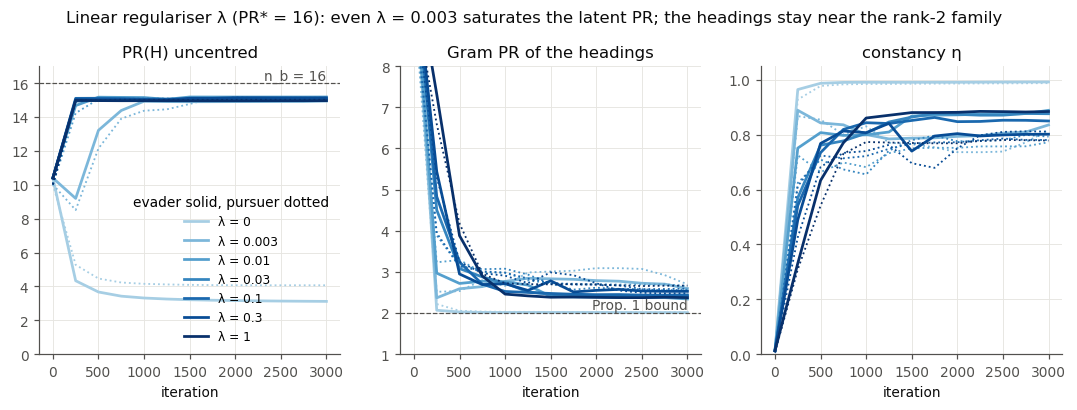

In [4]:
lin = sorted([(r["cfg"]["lam_pr"], t) for t, r in runs.items()
              if r["cfg"]["seed"] == 0 and r["cfg"]["iters"] == 3000 and not r["cfg"]["pr_centred"]
              and r["cfg"]["pr_form"] == "linear"])
blues = plt.cm.Blues(np.linspace(0.35, 1.0, len(lin)))        # sequential ramp: λ is a magnitude
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for (lam, t), col in zip(lin, blues):
    h = runs[t]["hist"]; it = [x["it"] for x in h]
    for k, (key, ttl) in enumerate((("pr_H_unc", "PR(H) uncentred"), ("gram_pr", "Gram PR of the headings"), ("constancy", "constancy η"))):
        axs[k].plot(it, [x["E"][key] for x in h], color=col, lw=1.8, label=f"λ = {lam:g}" if k == 0 else None)
        axs[k].plot(it, [x["P"][key] for x in h], color=col, lw=1.2, ls=":")
        axs[k].set_title(ttl, color=INK); axs[k].set_xlabel("iteration")
axs[0].axhline(N_B, color=INK2, lw=0.8, ls="--"); axs[0].text(3000, N_B + 0.2, "n_b = 16", ha="right", color=INK2)
axs[1].axhline(2, color=INK2, lw=0.8, ls="--"); axs[1].text(3000, 2.1, "Prop. 1 bound", ha="right", color=INK2)
axs[0].legend(title="evader solid, pursuer dotted", loc="lower right", fontsize=8)
axs[0].set_ylim(0, 17); axs[1].set_ylim(1, 8); axs[2].set_ylim(0, 1.05)
fig.suptitle("Linear regulariser λ (PR* = 16): even λ = 0.003 saturates the latent PR; the headings stay near the rank-2 family", color=INK, y=1.03)
savefig(fig, "fig1_linear_training_curves.png"); plt.show()


## 4. Endpoints against λ, both forms, all seeds

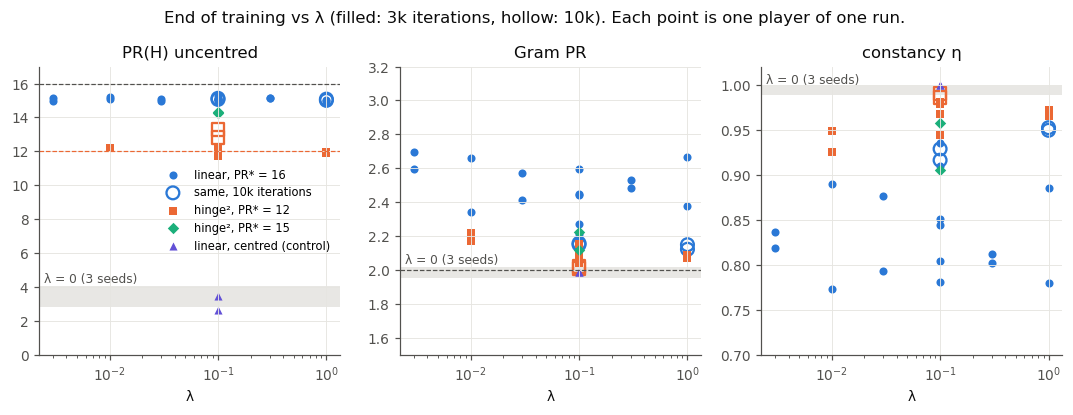

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
groups = [("linear, PR* = 16", lambda c: c["pr_form"] == "linear" and not c["pr_centred"], C[0], "o"),
          ("hinge², PR* = 12", lambda c: c["pr_form"] == "hinge2" and c["pr_target"] == 12, C[1], "s"),
          ("hinge², PR* = 15", lambda c: c["pr_form"] == "hinge2" and c["pr_target"] == 15, C[2], "D"),
          ("linear, centred (control)", lambda c: c["pr_centred"], C[6], "^")]
base = df[df.lam == 0]
for k, (key, ttl) in enumerate((("pr_H_unc", "PR(H) uncentred"), ("gram_pr", "Gram PR"), ("constancy", "constancy η"))):
    ax = axs[k]
    ax.axhspan(base[key].min(), base[key].max(), color=GRID, alpha=0.9, lw=0)
    ax.text(0.0025, base[key].max(), "λ = 0 (3 seeds)", color=INK2, fontsize=8, va="bottom")
    for name, sel, col, mk in groups:
        sub = df[(df.lam > 0) & df.apply(lambda r: sel(runs["pilot_integ_tmax1.5_" + r["run"]]["cfg"]), axis=1)]
        s3 = sub[sub.iters == 3000]; s10 = sub[sub.iters > 3000]
        ax.scatter(s3.lam, s3[key], color=col, marker=mk, s=28, lw=0, label=name if k == 0 else None)
        ax.scatter(s10.lam, s10[key], facecolor="none", edgecolor=col, marker=mk, s=70, lw=1.5,
                   label=("same, 10k iterations" if name.startswith("linear, PR") else None) if k == 0 else None)
    ax.set_xscale("log"); ax.set_xlabel("λ"); ax.set_title(ttl, color=INK)
axs[0].axhline(16, color=INK2, lw=0.8, ls="--"); axs[0].axhline(12, color=C[1], lw=0.8, ls="--")
axs[1].axhline(2, color=INK2, lw=0.8, ls="--"); axs[0].set_ylim(0, 17); axs[1].set_ylim(1.5, 3.2); axs[2].set_ylim(0.7, 1.02)
axs[0].legend(fontsize=7.5, loc="center right")
fig.suptitle("End of training vs λ (filled: 3k iterations, hollow: 10k). Each point is one player of one run.", color=INK, y=1.03)
savefig(fig, "fig2_endpoints_vs_lambda.png"); plt.show()


## 5. What the regulariser does to the latent: eigenvalue spectra

Filled bars: eigenvalues of the uncentred second moment $\langle HH^\top\rangle_t$. Outlined bars: eigenvalues of the centred covariance. Each spectrum is normalised to sum 1 so the shapes are comparable; the PR is the effective number of equal bars.

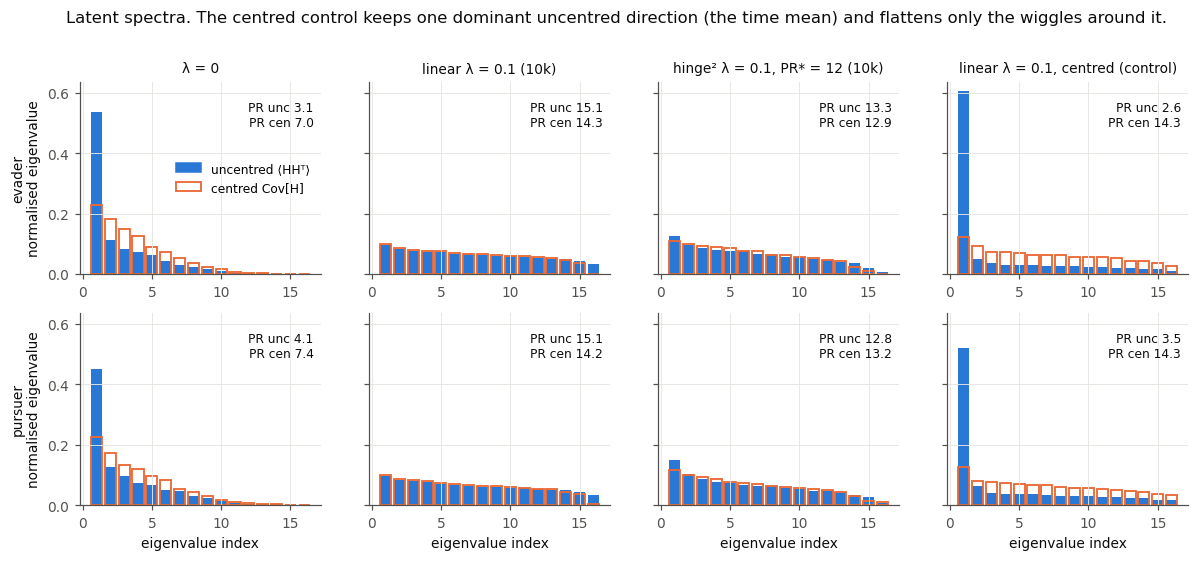

In [6]:
show = [("pilot_integ_tmax1.5_s0", "λ = 0"), ("pilot_integ_tmax1.5_s0_lampr0.1_it10k", "linear λ = 0.1 (10k)"),
        ("pilot_integ_tmax1.5_s0_lampr0.1_hinge2_tgt12_it10k", "hinge² λ = 0.1, PR* = 12 (10k)"),
        ("pilot_integ_tmax1.5_s0_lampr0.1c", "linear λ = 0.1, centred (control)")]
fig, axs = plt.subplots(2, 4, figsize=(13, 5), sharey=True)
x = np.arange(1, N_B + 1)
for j, (t, ttl) in enumerate(show):
    for i, a in enumerate("EP"):
        m = runs[t]["mech"][a]; ax = axs[i, j]
        eu = m["ev_unc"] / m["ev_unc"].sum(); ec = m["ev_cen"] / m["ev_cen"].sum()
        ax.bar(x, eu, color=C[0], width=0.8, lw=0)
        ax.bar(x, ec, facecolor="none", edgecolor=C[1], width=0.8, lw=1.2)
        ax.text(0.97, 0.9, f"PR unc {m['pr_H_unc']:.1f}\nPR cen {m['pr_H']:.1f}", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=INK)
        if i == 0: ax.set_title(ttl, color=INK, fontsize=9)
        if j == 0: ax.set_ylabel(f"{'evader' if a == 'E' else 'pursuer'}\nnormalised eigenvalue")
        if i == 1: ax.set_xlabel("eigenvalue index")
from matplotlib.patches import Patch
axs[0, 0].legend(handles=[Patch(color=C[0], label="uncentred ⟨HHᵀ⟩"), Patch(facecolor="none", edgecolor=C[1], lw=1.2, label="centred Cov[H]")],
                 fontsize=8, loc="center right")
fig.suptitle("Latent spectra. The centred control keeps one dominant uncentred direction (the time mean) and flattens only the wiggles around it.", color=INK, y=1.01)
savefig(fig, "fig3_latent_spectra.png"); plt.show()


## 6. What the regulariser does to the heads: they go rank 1

Each dot is one head. A head with $s_2/s_1 = 0$ maps the whole 16-dimensional latent onto a single line in $\mathbb{R}^2$, so its heading can only be $\pm e^j$ and all latent variation ends up in $|z^j(t)|$, which the normalisation throws away.

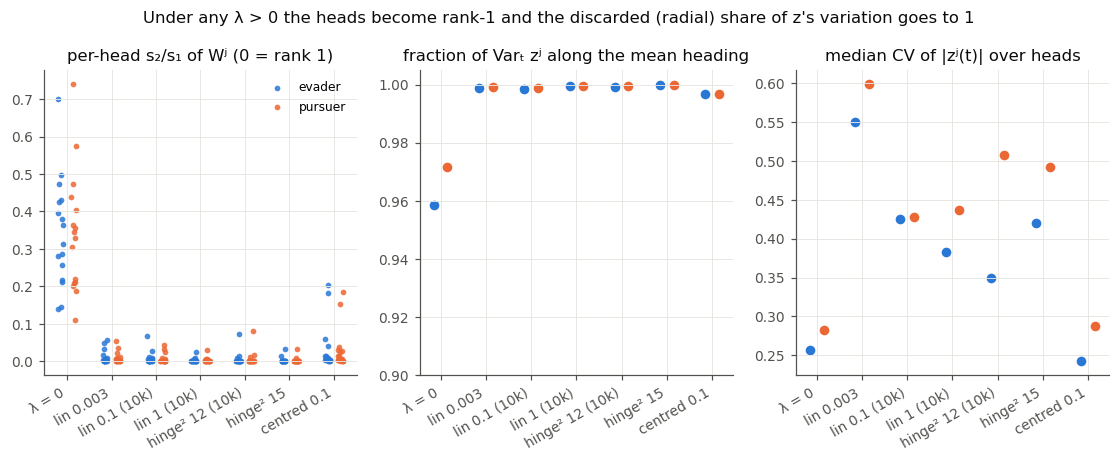

In [7]:
sel = [("pilot_integ_tmax1.5_s0", "λ = 0"), ("pilot_integ_tmax1.5_s0_lampr0.003", "lin 0.003"),
       ("pilot_integ_tmax1.5_s0_lampr0.1_it10k", "lin 0.1 (10k)"), ("pilot_integ_tmax1.5_s0_lampr1_it10k", "lin 1 (10k)"),
       ("pilot_integ_tmax1.5_s0_lampr0.1_hinge2_tgt12_it10k", "hinge² 12 (10k)"), ("pilot_integ_tmax1.5_s0_lampr0.1_hinge2_tgt15", "hinge² 15"),
       ("pilot_integ_tmax1.5_s0_lampr0.1c", "centred 0.1")]
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6))
rng = np.random.default_rng(0)
for k, (t, ttl) in enumerate(sel):
    for i, a in enumerate("EP"):
        m = runs[t]["mech"][a]; xx = k + (-0.15 if a == "E" else 0.15) + rng.uniform(-0.06, 0.06, 16)
        axs[0].scatter(xx, m["ratio"], s=14, color=C[i], lw=0, alpha=0.85, label=("evader", "pursuer")[i] if k == 0 else None)
        axs[1].scatter(k + (-0.15 if a == "E" else 0.15), m["radial_frac"], s=40, color=C[i], lw=0)
        axs[2].scatter(k + (-0.15 if a == "E" else 0.15), m["cv_absz"], s=40, color=C[i], lw=0)
for ax, ttl in zip(axs, ("per-head s₂/s₁ of Wʲ (0 = rank 1)", "fraction of Varₜ zʲ along the mean heading", "median CV of |zʲ(t)| over heads")):
    ax.set_xticks(range(len(sel))); ax.set_xticklabels([s[1] for s in sel], rotation=30, ha="right"); ax.set_title(ttl, color=INK)
axs[0].legend(fontsize=8); axs[1].set_ylim(0.9, 1.005)
fig.suptitle("Under any λ > 0 the heads become rank-1 and the discarded (radial) share of z's variation goes to 1", color=INK, y=1.03)
savefig(fig, "fig4_head_rank.png"); plt.show()


## 7. The mechanism head by head: $|z^j(t)|$ and the heading angle

Four heads of the evader, λ = 0 against linear λ = 0.1 (3k iterations). With the regulariser, $|z^j(t)|$ swings by a factor of several while the angle stays flat except for 180° jumps where $w^j\cdot H(t)$ crosses zero.

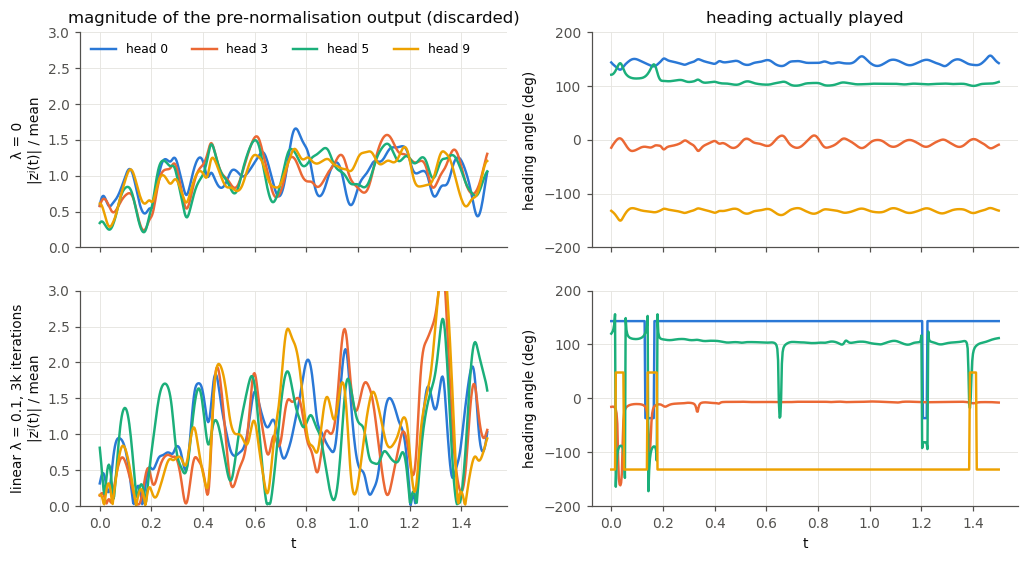

In [8]:
pair = [("pilot_integ_tmax1.5_s0", "λ = 0"), ("pilot_integ_tmax1.5_s0_lampr0.1", "linear λ = 0.1, 3k iterations")]
heads = [0, 3, 5, 9]
fig, axs = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True)
for i, (t, ttl) in enumerate(pair):
    m = runs[t]["mech"]["E"]; u, z = m["u"], m["z"]
    for k, j in enumerate(heads):
        nz = np.linalg.norm(z[j], axis=-1)
        ang = np.degrees(np.arctan2(u[j, :, 1], u[j, :, 0]))
        axs[i, 0].plot(tdense, nz / nz.mean(), color=C[k], lw=1.6, label=f"head {j}")
        axs[i, 1].plot(tdense, ang, color=C[k], lw=1.6)
    axs[i, 0].set_ylabel(ttl + "\n|zʲ(t)| / mean"); axs[i, 1].set_ylabel("heading angle (deg)")
    axs[i, 0].set_ylim(0, 3); axs[i, 1].set_ylim(-200, 200)
axs[0, 0].legend(fontsize=8, ncol=4, loc="upper left"); axs[1, 0].set_xlabel("t"); axs[1, 1].set_xlabel("t")
axs[0, 0].set_title("magnitude of the pre-normalisation output (discarded)", color=INK); axs[0, 1].set_title("heading actually played", color=INK)
savefig(fig, "fig5_mechanism_heads.png"); plt.show()


## 8. The residual constancy loss is sign flips, nothing else

If a rank-1 head spends a fraction $f_j$ of the time flipped, $|\langle\hat u^j\rangle_t| = |1-2f_j|$ and $\eta = \overline{(1-2f_j)^2}$. The prediction from the flip fractions alone matches the measured $\eta$ on every regularised run.

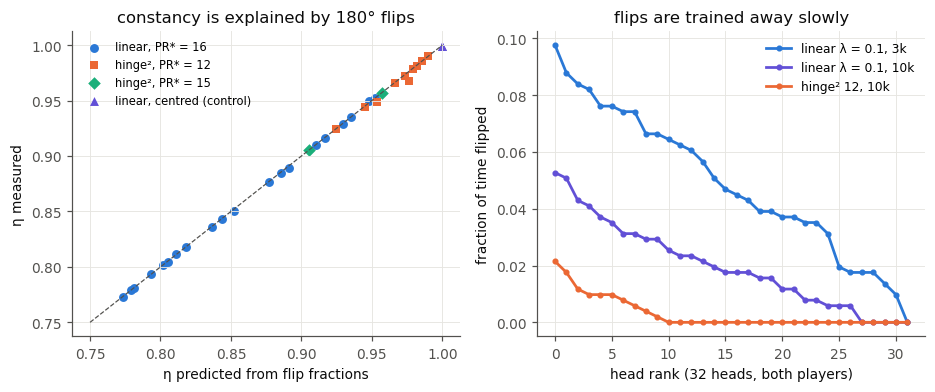

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for name, sel_fn, col, mk in groups:
    sub = df[(df.lam > 0) & df.apply(lambda r: sel_fn(runs["pilot_integ_tmax1.5_" + r["run"]]["cfg"]), axis=1)]
    axs[0].scatter(sub.eta_from_flips, sub.constancy, color=col, marker=mk, s=34, lw=0, label=name)
axs[0].plot([0.75, 1], [0.75, 1], color=INK2, lw=0.8, ls="--"); axs[0].set_xlabel("η predicted from flip fractions"); axs[0].set_ylabel("η measured")
axs[0].set_title("constancy is explained by 180° flips", color=INK); axs[0].legend(fontsize=7.5, loc="upper left")
for t, ttl, col in (("pilot_integ_tmax1.5_s0_lampr0.1", "linear λ = 0.1, 3k", C[0]), ("pilot_integ_tmax1.5_s0_lampr0.1_it10k", "linear λ = 0.1, 10k", C[6]),
                    ("pilot_integ_tmax1.5_s0_lampr0.1_hinge2_tgt12_it10k", "hinge² 12, 10k", C[1])):
    ff = np.concatenate([runs[t]["mech"][a]["f_flip"] for a in "EP"])
    axs[1].plot(np.sort(ff)[::-1], color=col, lw=1.8, marker="o", ms=3, label=ttl)
axs[1].set_xlabel("head rank (32 heads, both players)"); axs[1].set_ylabel("fraction of time flipped"); axs[1].set_title("flips are trained away slowly", color=INK)
axs[1].legend(fontsize=8)
savefig(fig, "fig6_flips.png"); plt.show()


## 9. Hinge-squared form, $R=\lambda\max(0, \mathrm{PR}^*-\mathrm{PR}(H))^2$ with $\mathrm{PR}^*=12$

The term is active only while $\mathrm{PR}(H) < 12$. It parks the uncentred PR at the target and then has zero gradient, so the game alone shapes everything else.

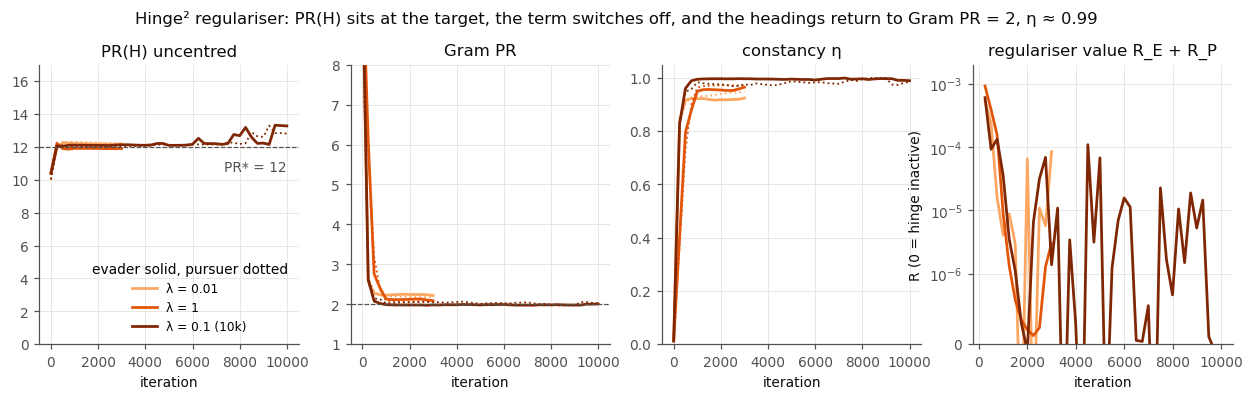

In [10]:
hs = sorted([(r["cfg"]["lam_pr"], t) for t, r in runs.items() if r["cfg"]["pr_form"] == "hinge2" and r["cfg"]["pr_target"] == 12
             and r["cfg"]["seed"] == 0 and r["cfg"]["iters"] == 3000])
hs.append((0.1, "pilot_integ_tmax1.5_s0_lampr0.1_hinge2_tgt12_it10k"))
ora = plt.cm.Oranges(np.linspace(0.4, 1.0, len(hs)))
fig, axs = plt.subplots(1, 4, figsize=(14, 3.3))
for (lam, t), col in zip(hs, ora):
    h = runs[t]["hist"]; it = [x["it"] for x in h]
    lab = f"λ = {lam:g}" + (" (10k)" if "10k" in t else "")
    for k, key in enumerate(("pr_H_unc", "gram_pr", "constancy")):
        axs[k].plot(it, [x["E"][key] for x in h], color=col, lw=1.8, label=lab if k == 0 else None)
        axs[k].plot(it, [x["P"][key] for x in h], color=col, lw=1.2, ls=":")
    axs[3].plot(it[1:], [x["R_E"] + x["R_P"] for x in h[1:]], color=col, lw=1.8)
for ax, ttl in zip(axs, ("PR(H) uncentred", "Gram PR", "constancy η", "regulariser value R_E + R_P")):
    ax.set_title(ttl, color=INK); ax.set_xlabel("iteration")
axs[0].axhline(12, color=INK2, lw=0.8, ls="--"); axs[0].text(10000, 11.2, "PR* = 12", ha="right", va="top", color=INK2)
axs[1].axhline(2, color=INK2, lw=0.8, ls="--"); axs[0].set_ylim(0, 17); axs[1].set_ylim(1, 8); axs[2].set_ylim(0, 1.05)
axs[3].set_yscale("symlog", linthresh=1e-6); axs[3].set_ylim(0, 2e-3); axs[3].set_ylabel("R (0 = hinge inactive)")
axs[0].legend(fontsize=8, loc="lower right", title="evader solid, pursuer dotted")
fig.suptitle("Hinge² regulariser: PR(H) sits at the target, the term switches off, and the headings return to Gram PR = 2, η ≈ 0.99", color=INK, y=1.03)
savefig(fig, "fig7_hinge2.png"); plt.show()


## 10. Compact table for the notes

In [11]:
cols = ["label", "seed", "iters", "player", "pr_H", "pr_H_unc", "gram_pr", "constancy", "s2s1_med", "radial_frac", "J"]
tab = df[cols].copy()
tab.columns = ["run", "seed", "iters", "pl", "PR(H) cen", "PR(H) unc", "Gram PR", "η", "s₂/s₁ med", "radial frac", "J"]
tab.round(3)


,run,seed,iters,pl,PR(H) cen,PR(H) unc,Gram PR,η,s₂/s₁ med,radial frac,J
0,hinge2 λ=0.01 PR*=12,0,3000,E,12.321,12.178,2.218,0.925,0.044,0.997,0.774
1,hinge2 λ=0.01 PR*=12,0,3000,P,12.173,12.214,2.168,0.949,0.073,0.996,0.774
2,hinge2 λ=0.1 PR*=12,0,10000,E,12.887,13.273,2.008,0.990,0.000,0.999,0.760
3,hinge2 λ=0.1 PR*=12,0,10000,P,13.231,12.808,2.022,0.985,0.000,1.000,0.760
4,hinge2 λ=0.1 PR*=12,1,3000,E,12.314,11.783,2.150,0.945,0.008,1.000,0.751
5,hinge2 λ=0.1 PR*=12,1,3000,P,12.311,11.706,2.055,0.979,0.010,0.999,0.751
6,hinge2 λ=0.1 PR*=12,2,3000,E,11.829,12.047,2.038,0.981,0.048,0.998,0.751
7,hinge2 λ=0.1 PR*=12,2,3000,P,12.084,12.172,2.100,0.968,0.166,0.974,0.751
8,hinge2 λ=1 PR*=12,0,3000,E,12.163,11.901,2.090,0.965,0.004,0.999,0.760
9,hinge2 λ=1 PR*=12,0,3000,P,12.320,11.963,2.071,0.972,0.000,0.997,0.760


## Conclusions

1. **The regulariser costs the game nothing.** Both forms reach their target PR(H) within the first few hundred iterations and $J$ stays at the saddle-ish value 0.75–0.77 of the unregularised runs.
2. **The rank-2 reduction of the heading ensemble survives.** With uncentred PR(H) forced to 15/16 (linear) or 12/16 (hinge²), Gram PR comes back to 2.0–2.2 and constancy to 0.92–0.99 by 10k iterations. The hinge² form with PR* = 12 gives Gram PR 2.01 / 2.02 and $\eta$ = 0.99 / 0.985 at 10k.
3. **Mechanism.** The heads become exactly rank 1 ($s_2/s_1 \to 0$ for every head). A rank-1 head plays $\hat u^j = \operatorname{sign}(w^j\cdot H)\, e^j$: the heading is fixed and all latent variation lands in $|z^j(t)|$, which the normalisation discards (radial fraction 99.9–100 %). The remaining constancy loss is 180° sign flips where $w^j \cdot H$ crosses zero, and it is removed by training because a flipped stretch is maximally bad play.
4. **Centred vs uncentred.** Regularising the centred PR is a loophole: the body keeps a large constant mean plus tiny isotropic wiggles, so centred PR reads 14 while the uncentred PR stays at 3 and nothing changes in the game. The uncentred moment is the one that talks to the heading ensemble, and it is the one to constrain and to report.
5. **For the paper.** "PR(H) small" and "Gram PR = 2" are logically independent in this architecture, because linear heads plus a normalisation can route any number of latent directions into the discarded radial component. A latent-PR number cannot on its own support "the embedding reduces to the game's dimension"; the gauge-fixed head rank and the Gram PR are the objects that do.
